# Entrenamiento y evaluación de los tres modelos predictivos (Carroya)

## Objetivo
Entrenar, ajustar y evaluar los tres modelos del sistema predictivo, y guardarlos listos para que los cargue el backend.

| # | Modelo | Algoritmo | Variable objetivo |
|---|---|---|---|
| 1 | Regresión | Gradient Boosting (`HistGradientBoostingRegressor`) | `precio` (en pesos) |
| 2 | Regresión | Random Forest | `precio` (en pesos) |
| 3 | Clasificación | Regresión Logística | `segmento_precio` (BAJO / MEDIO / ALTO) |

Los tres usan **las mismas 10 variables de entrada** que pedirá el formulario, así que el backend puede alimentar los tres modelos con un único conjunto de datos.

## Reglas del notebook
1. **Entrada:** las particiones train/val/test que genera `Limpieza_Transformacion_Carroya.ipynb` (ejecútalo primero).
2. **Todo va dentro de un `Pipeline`:** preprocesamiento (el mismo módulo `preprocesamiento.py` del backend) + algoritmo. Cada modelo guardado recibe las 10 columnas crudas y se encarga del resto.
3. **Los hiperparámetros se buscan solo con entrenamiento**, con validación cruzada. La partición de validación sirve para comparar modelos y diagnosticar sobreajuste.
4. **La partición de prueba se usa una sola vez**, en la sección 7, con los modelos ya definitivos. Ninguna decisión se toma mirándola.
5. **Los modelos de regresión devuelven pesos directamente.** Se entrenan sobre `log(1 + precio)` y la transformación inversa va incluida en el modelo guardado, así que el backend solo llama a `predict`.

## Orden
1. Carga y verificación · 2. Métricas y baselines · 3. Modelo 1 · 4. Modelo 2 · 5. Modelo 3 · 6. Comparación entre modelos · 7. Resultados finales en prueba y sobreajuste · 8. Gráficos de diagnóstico · 9. Interpretación · 10. Indicadores de confianza · 11. Persistencia y prueba del flujo del backend.

## 1. Carga y verificación
Los parámetros de esfuerzo de la búsqueda están al inicio. Con `MODO_RAPIDO = True` se hace una prueba corta para comprobar que todo funciona; para los resultados del informe, déjalo en `False`.

In [2]:
import json
import platform
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.stats import loguniform, randint
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
                             precision_score, r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore", category=FutureWarning)
_v = tuple(int(x) for x in sklearn.__version__.split(".")[:2])
assert _v >= (1, 4), f"Se requiere scikit-learn >= 1.4 (tienes {sklearn.__version__})"
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---- Esfuerzo de la búsqueda de hiperparámetros
MODO_RAPIDO = False
N_ITER_GB, N_ITER_RF, CV_FOLDS = (20, 10, 3) if not MODO_RAPIDO else (3, 2, 2)
SEMILLA = 42

project_root = Path.cwd()
while not (project_root / "Scripts" / "data" / "procesado" / "carroya_train.csv").is_file():
    if project_root == project_root.parent:
        raise FileNotFoundError("No se encontraron las particiones. Ejecuta primero Limpieza_Transformacion_Carroya.ipynb.")
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "Scripts"))
import preprocesamiento as pp

carpeta_datos = project_root / "Scripts" / "data" / "procesado"
carpeta_modelos = project_root / "models"
carpeta_modelos.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(carpeta_datos / "carroya_train.csv", encoding="utf-8-sig")
val = pd.read_csv(carpeta_datos / "carroya_val.csv", encoding="utf-8-sig")
test = pd.read_csv(carpeta_datos / "carroya_test.csv", encoding="utf-8-sig")

esperadas = set(pp.COLS_ENTRADA + ["precio", "segmento_precio"])
for nombre, particion in (("train", train), ("val", val), ("test", test)):
    assert esperadas <= set(particion.columns), f"Faltan columnas en {nombre}: {esperadas - set(particion.columns)}"

X_train, X_val, X_test = train[pp.COLS_ENTRADA], val[pp.COLS_ENTRADA], test[pp.COLS_ENTRADA]
y_train, y_val, y_test = train["precio"], val["precio"], test["precio"]
s_train, s_val, s_test = train["segmento_precio"], val["segmento_precio"], test["segmento_precio"]

with open(carpeta_datos / "cortes_segmento.json", encoding="utf-8") as f:
    cortes_info = json.load(f)

print(f"train: {len(train):,} | val: {len(val):,} | test: {len(test):,}")
print(f"Entradas del modelo ({len(pp.COLS_ENTRADA)}): {pp.COLS_ENTRADA}")
print(f"Cortes de segmento: BAJO <= {cortes_info['cortes'][0]:,.0f} < MEDIO <= {cortes_info['cortes'][1]:,.0f} < ALTO")
print(f"Búsqueda: GB {N_ITER_GB} combinaciones, RF {N_ITER_RF} combinaciones, {CV_FOLDS} particiones de validación cruzada")

train: 14,261 | val: 3,056 | test: 3,056
Entradas del modelo (10): ['marca', 'modelo', 'anio', 'kilometraje', 'combustible', 'transmision', 'cilindraje', 'carroceria', 'departamento', 'tipo_vendedor']
Cortes de segmento: BAJO <= 43,333,333 < MEDIO <= 73,000,000 < ALTO
Búsqueda: GB 20 combinaciones, RF 10 combinaciones, 3 particiones de validación cruzada


## 2. Métricas y modelos base (baseline)
Un modelo solo es bueno si supera a uno trivial. Los baselines son:

- **Regresión:** predecir siempre la mediana del precio de entrenamiento.
- **Clasificación:** predecir siempre según la proporción de clases de entrenamiento.

**Métricas de regresión** (siempre en pesos): MAE, RMSE, MAPE (error porcentual medio) y R². Se agrega R² sobre `log(precio)`, que mide qué tan bien se ordena el precio sin que los carros muy caros dominen.
**Métricas de clasificación:** exactitud, precisión, exhaustividad (recall) y F1 (macro, porque las tres clases pesan igual), AUC-ROC (uno contra el resto, macro) y matriz de confusión.

In [3]:
def metricas_regresion(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
        "MAPE_%": mean_absolute_percentage_error(y_real, y_pred) * 100,
        "R2": r2_score(y_real, y_pred),
        "R2_log": r2_score(np.log1p(y_real), np.log1p(y_pred)),
    }

def metricas_clasificacion(modelo, X, y):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y, pred, average="macro", zero_division=0),
        "AUC_ROC_macro": roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=modelo.classes_),
    }

def construir_pipeline_modelo(estimador):
    # Preprocesamiento compartido con el backend + algoritmo
    return Pipeline([
        ("preprocesamiento", pp.construir_pipeline_preprocesamiento()),
        ("modelo", estimador),
    ])

def regresor_log(estimador):
    # El modelo se entrena sobre log(1 + precio) pero predice directamente en pesos
    return TransformedTargetRegressor(
        regressor=construir_pipeline_modelo(estimador), func=np.log1p, inverse_func=np.expm1
    )

def tabla_busqueda(busqueda, es_regresion):
    cv = pd.DataFrame(busqueda.cv_results_).sort_values("rank_test_score").head(5)
    signo = -1 if es_regresion else 1
    columnas_param = [c for c in cv.columns if c.startswith("param_")]
    salida = cv[columnas_param].copy()
    salida.columns = [c.replace("param_regressor__modelo__", "").replace("param_modelo__", "") for c in columnas_param]
    salida.insert(0, "score_validacion_cruzada", signo * cv["mean_test_score"].values)
    salida.insert(1, "desv_estandar", cv["std_test_score"].values)
    salida.insert(2, "score_entrenamiento", signo * cv["mean_train_score"].values)
    return salida

base_reg = DummyRegressor(strategy="median").fit(X_train, y_train)
base_clf = DummyClassifier(strategy="prior").fit(X_train, s_train)

display(pd.DataFrame({
    "Baseline regresión (mediana)": metricas_regresion(y_val, base_reg.predict(X_val)),
}).T)
display(pd.DataFrame({
    "Baseline clasificación (proporción de clases)": metricas_clasificacion(base_clf, X_val, s_val),
}).T)

,MAE,RMSE,MAPE_%,R2,R2_log
Baseline regresión (mediana),"33,726,833.930","60,143,282.646",55.489,-0.060,-0.000


,accuracy,precision_macro,recall_macro,F1_macro,AUC_ROC_macro
Baseline clasificación (proporción de clases),0.339,0.113,0.333,0.169,0.500


## 3. Modelo 1: regresión de `precio` con Gradient Boosting

**Por qué este algoritmo.** El Gradient Boosting construye árboles uno tras otro, cada uno corrigiendo los errores del anterior. Suele ser el mejor algoritmo en datos tabulares con relaciones no lineales (el precio no baja en línea recta con el kilometraje) e interacciones (el efecto del año depende de la marca). Maneja bien escalas distintas y no exige que las variables sean normales. Se usa la versión por histogramas de scikit-learn (`HistGradientBoostingRegressor`), rápida y sin dependencias extra.

**Hiperparámetros explorados** (búsqueda aleatoria con validación cruzada, sobre entrenamiento):

| Hiperparámetro | Rango | Qué controla |
|---|---|---|
| `learning_rate` | 0,03 a 0,3 (escala logarítmica) | Cuánto corrige cada árbol; bajo = más preciso pero más lento |
| `max_leaf_nodes` | 15 a 63 | Complejidad de cada árbol |
| `min_samples_leaf` | 10 a 59 | Mínimo de avisos por hoja; evita memorizar casos sueltos |
| `max_depth` | sin límite, 4, 6 u 8 | Profundidad máxima |
| `l2_regularization` | 0,001 a 10 (escala logarítmica) | Penaliza ajustes extremos |

El número de árboles no se busca: se fija un máximo de 1.000 y se detiene solo (parada temprana) cuando deja de mejorar, lo que evita sobreajuste. El criterio de selección es el RMSE sobre `log(1 + precio)` (RMSLE), que penaliza el error relativo y no solo el absoluto.

In [4]:
espacio_gb = {
    "regressor__modelo__learning_rate": loguniform(0.03, 0.3),
    "regressor__modelo__max_leaf_nodes": randint(15, 64),
    "regressor__modelo__min_samples_leaf": randint(10, 60),
    "regressor__modelo__max_depth": [None, 4, 6, 8],
    "regressor__modelo__l2_regularization": loguniform(1e-3, 10),
}
gb_base = regresor_log(HistGradientBoostingRegressor(
    max_iter=1000, early_stopping=True, n_iter_no_change=20, validation_fraction=0.1, random_state=SEMILLA
))
busqueda_gb = RandomizedSearchCV(
    gb_base, espacio_gb, n_iter=N_ITER_GB, cv=CV_FOLDS, scoring="neg_root_mean_squared_log_error",
    random_state=SEMILLA, n_jobs=1, return_train_score=True,
)
t0 = time.time()
busqueda_gb.fit(X_train, y_train)
print(f"Búsqueda terminada en {time.time() - t0:,.0f} s")
print("Mejores hiperparámetros:", {k.replace("regressor__modelo__", ""): v for k, v in busqueda_gb.best_params_.items()})
print(f"RMSLE en validación cruzada: {-busqueda_gb.best_score_:.4f}")
display(tabla_busqueda(busqueda_gb, es_regresion=True))

modelo_gb = busqueda_gb.best_estimator_
gb_val = metricas_regresion(y_val, modelo_gb.predict(X_val))
gb_train = metricas_regresion(y_train, modelo_gb.predict(X_train))
display(pd.DataFrame({"train": gb_train, "val": gb_val}).T)

Búsqueda terminada en 310 s
Mejores hiperparámetros: {'l2_regularization': np.float64(0.02161894240657444), 'learning_rate': np.float64(0.0416857934827831), 'max_depth': 6, 'max_leaf_nodes': 36, 'min_samples_leaf': 11}
RMSLE en validación cruzada: 0.1878


,score_validacion_cruzada,desv_estandar,score_entrenamiento,l2_regularization,learning_rate,max_depth,max_leaf_nodes,min_samples_leaf
2,0.188,0.003,0.151,0.022,0.042,6,36,11
5,0.188,0.002,0.151,0.126,0.075,8,42,25
7,0.189,0.003,0.133,2.753,0.144,None,53,27
15,0.189,0.002,0.149,0.036,0.056,None,38,35
18,0.189,0.004,0.160,0.038,0.059,6,25,26


,MAE,RMSE,MAPE_%,R2,R2_log
train,"7,378,497.275","18,689,279.131",10.005,0.888,0.945
val,"9,332,910.546","22,565,612.854",12.356,0.851,0.914


## 4. Modelo 2: regresión de `precio` con Random Forest

**Por qué este algoritmo.** El Random Forest promedia cientos de árboles entrenados con muestras y variables distintas. Es robusto a valores atípicos, casi no necesita ajuste fino y sirve como contraste con el boosting: los dos modelos de regresión son de familias distintas (promedio de árboles independientes frente a árboles que se corrigen entre sí), así que comparar sus resultados es informativo y su acuerdo o desacuerdo sirve como indicador de confianza en el frontend.

**Hiperparámetros explorados:**

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `n_estimators` | 100 o 200 | Número de árboles; más árboles reducen la varianza |
| `max_depth` | 12, 20 o 30 | Profundidad máxima de cada árbol |
| `min_samples_leaf` | 5, 8, 12 o 20 | Mínimo de avisos por hoja; valores altos suavizan |
| `max_features` | raíz cuadrada, 20 % o 33 % de las columnas | Variables que ve cada división; menos variables decorrelaciona los árboles |

**Por qué hojas de al menos 5 avisos y profundidad acotada.** Un Random Forest con hojas de 1 aviso y profundidad ilimitada memoriza el entrenamiento, y además su archivo guardado puede pesar cientos de MB (GitHub rechaza archivos de más de 100 MB y el backend tardaría en cargarlo). Acotar el tamaño de las hojas regulariza el modelo y mantiene el archivo manejable.

Mismo criterio de selección que el modelo 1 (RMSLE en validación cruzada) para que la comparación sea justa.

In [5]:
espacio_rf = {
    "regressor__modelo__n_estimators": [100, 200],
    "regressor__modelo__max_depth": [12, 20, 30],
    "regressor__modelo__min_samples_leaf": [5, 8, 12, 20],
    "regressor__modelo__max_features": ["sqrt", 0.2, 0.33],
}
rf_base = regresor_log(RandomForestRegressor(n_jobs=-1, random_state=SEMILLA))
busqueda_rf = RandomizedSearchCV(
    rf_base, espacio_rf, n_iter=N_ITER_RF, cv=CV_FOLDS, scoring="neg_root_mean_squared_log_error",
    random_state=SEMILLA, n_jobs=1, return_train_score=True,
)
t0 = time.time()
busqueda_rf.fit(X_train, y_train)
print(f"Búsqueda terminada en {time.time() - t0:,.0f} s")
print("Mejores hiperparámetros:", {k.replace("regressor__modelo__", ""): v for k, v in busqueda_rf.best_params_.items()})
print(f"RMSLE en validación cruzada: {-busqueda_rf.best_score_:.4f}")
display(tabla_busqueda(busqueda_rf, es_regresion=True))

modelo_rf = busqueda_rf.best_estimator_
rf_val = metricas_regresion(y_val, modelo_rf.predict(X_val))
rf_train = metricas_regresion(y_train, modelo_rf.predict(X_train))
display(pd.DataFrame({"train": rf_train, "val": rf_val}).T)

Búsqueda terminada en 80 s
Mejores hiperparámetros: {'n_estimators': 100, 'min_samples_leaf': 8, 'max_features': 0.33, 'max_depth': 12}
RMSLE en validación cruzada: 0.2280


,score_validacion_cruzada,desv_estandar,score_entrenamiento,n_estimators,min_samples_leaf,max_features,max_depth
2,0.228,0.003,0.203,100,8,0.330,12
7,0.229,0.005,0.205,100,8,0.200,20
6,0.238,0.004,0.219,100,8,0.200,12
8,0.246,0.004,0.230,100,12,0.200,12
1,0.254,0.004,0.243,100,20,0.200,30


,MAE,RMSE,MAPE_%,R2,R2_log
train,"10,659,670.082","26,974,013.255",13.802,0.767,0.897
val,"12,292,466.231","31,470,803.575",15.557,0.710,0.873


## 5. Modelo 3: clasificación del segmento de precio con Regresión Logística

**Qué responde.** Si un carro con esas características cae en el segmento BAJO, MEDIO o ALTO del mercado (terciles del precio de entrenamiento). Complementa a la regresión: no da un número, sino una categoría con una **probabilidad por clase**, que el frontend puede mostrar como indicador de confianza.

**Por qué este algoritmo.** La Regresión Logística multinomial es un modelo lineal: combina las variables con pesos y convierte el resultado en una probabilidad por clase. Se eligió por cuatro razones:

- **Tercera familia de algoritmos.** Los modelos 1 y 2 son de árboles; este es lineal, así que el conjunto de tres modelos es realmente diverso.
- **Rinde igual que un modelo más complejo.** En validación, su F1 macro (0,854 con la configuración inicial) fue igual o ligeramente superior al del Random Forest (0,846), y su diferencia entre entrenamiento y validación es mucho menor (0,006 frente a 0,040), es decir, es más estable.
- **Probabilidades bien comportadas** con `predict_proba`, útiles como indicador de confianza.
- **Simple, rápida e interpretable;** el archivo guardado es diminuto.

Funciona bien porque el preprocesador ya deja las variables en escala comparable (`RobustScaler` en las numéricas, One-Hot en las categóricas). Las tres clases están balanceadas por construcción (terciles), así que no hace falta ponderarlas.

**Hiperparámetro explorado.** La Regresión Logística tiene un hiperparámetro principal, `C`, la inversa de la regularización L2: un `C` bajo da un modelo más simple y suavizado, y uno alto se ajusta más al entrenamiento. Se explora en malla con validación cruzada, sobre entrenamiento:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `C` | 0,01 · 0,03 · 0,1 · 0,3 · 1 · 3 · 10 · 30 | Fuerza de la regularización (menor `C`, más regularización) |

El criterio de selección es el F1 macro, que trata igual a las tres clases. Como referencia se entrena además un **Random Forest** con parámetros fijos (sin búsqueda), para comprobar cuánto aporta la no linealidad.

In [6]:
espacio_clf = {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]}
clf_base = construir_pipeline_modelo(LogisticRegression(max_iter=1000))
busqueda_clf = GridSearchCV(
    clf_base, espacio_clf, cv=CV_FOLDS, scoring="f1_macro", n_jobs=1, return_train_score=True, verbose=2,
)
t0 = time.time()
busqueda_clf.fit(X_train, s_train)
print(f"Búsqueda terminada en {time.time() - t0:,.0f} s")
print("Mejor hiperparámetro:", {k.replace("modelo__", ""): v for k, v in busqueda_clf.best_params_.items()})
print(f"F1 macro en validación cruzada: {busqueda_clf.best_score_:.4f}")
display(tabla_busqueda(busqueda_clf, es_regresion=False))

modelo_clf = busqueda_clf.best_estimator_
clf_val = metricas_clasificacion(modelo_clf, X_val, s_val)
clf_train = metricas_clasificacion(modelo_clf, X_train, s_train)
display(pd.DataFrame({"train": clf_train, "val": clf_val}).T)

# Referencia: Random Forest con parámetros fijos (sin búsqueda)
rf_clf_ref = construir_pipeline_modelo(RandomForestClassifier(
    n_estimators=200, max_depth=20, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=SEMILLA
)).fit(X_train, s_train)
rf_clf_val = metricas_clasificacion(rf_clf_ref, X_val, s_val)
display(pd.DataFrame({"Random Forest (referencia), val": rf_clf_val}).T)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END .....................................modelo__C=0.01; total time=  26.4s
[CV] END .....................................modelo__C=0.01; total time=   8.2s
[CV] END .....................................modelo__C=0.01; total time=   1.1s
[CV] END .....................................modelo__C=0.03; total time=   3.9s
[CV] END .....................................modelo__C=0.03; total time=   4.0s
[CV] END .....................................modelo__C=0.03; total time=   0.9s
[CV] END ......................................modelo__C=0.1; total time=   1.0s
[CV] END ......................................modelo__C=0.1; total time=   1.0s
[CV] END ......................................modelo__C=0.1; total time=   1.4s
[CV] END ......................................modelo__C=0.3; total time=   1.2s
[CV] END ......................................modelo__C=0.3; total time=   2.1s
[CV] END ......................................mo

,score_validacion_cruzada,desv_estandar,score_entrenamiento,C
7,0.842,0.006,0.856,30.000
6,0.841,0.006,0.855,10.000
5,0.841,0.006,0.854,3.000
4,0.839,0.005,0.851,1.000
3,0.834,0.005,0.846,0.300


,accuracy,precision_macro,recall_macro,F1_macro,AUC_ROC_macro
train,0.864,0.864,0.864,0.864,0.963
val,0.852,0.853,0.852,0.852,0.957


,accuracy,precision_macro,recall_macro,F1_macro,AUC_ROC_macro
"Random Forest (referencia), val",0.845,0.844,0.846,0.844,0.956


## 6. Comparación entre modelos en validación
Con los tres modelos ya ajustados, se compara en la partición de **validación** (la de prueba todavía no se ha tocado).

In [7]:
comparacion_reg = pd.DataFrame({
    "Baseline (mediana)": metricas_regresion(y_val, base_reg.predict(X_val)),
    "Modelo 1: Gradient Boosting": gb_val,
    "Modelo 2: Random Forest": rf_val,
}).T
display(comparacion_reg)

comparacion_clf = pd.DataFrame({
    "Baseline (proporción de clases)": metricas_clasificacion(base_clf, X_val, s_val),
    "Referencia: Random Forest": rf_clf_val,
    "Modelo 3: Regresión Logística": clf_val,
}).T
display(comparacion_clf)

mejor_reg = comparacion_reg.drop(index="Baseline (mediana)")["RMSE"].idxmin()
print(f"Menor RMSE en validación: {mejor_reg}")

,MAE,RMSE,MAPE_%,R2,R2_log
Baseline (mediana),"33,726,833.930","60,143,282.646",55.489,-0.060,-0.000
Modelo 1: Gradient Boosting,"9,332,910.546","22,565,612.854",12.356,0.851,0.914
Modelo 2: Random Forest,"12,292,466.231","31,470,803.575",15.557,0.710,0.873


,accuracy,precision_macro,recall_macro,F1_macro,AUC_ROC_macro
Baseline (proporción de clases),0.339,0.113,0.333,0.169,0.500
Referencia: Random Forest,0.845,0.844,0.846,0.844,0.956
Modelo 3: Regresión Logística,0.852,0.853,0.852,0.852,0.957


Menor RMSE en validación: Modelo 1: Gradient Boosting


## 7. Resultados finales en prueba y análisis de sobreajuste
Aquí se usa por **única vez** la partición de prueba. Se reportan las tres particiones lado a lado para diagnosticar:

- **Sobreajuste:** el modelo rinde mucho mejor en entrenamiento que en validación/prueba (error de entrenamiento muy bajo frente al de validación). Ojo: en los modelos de bosques de árboles el error de entrenamiento es siempre optimista, así que la señal fiable es la **validación cruzada** de las secciones 3 a 5 y que validación y prueba se parezcan.
- **Subajuste:** el modelo rinde mal incluso en entrenamiento, y apenas supera al baseline.
- **Buen ajuste:** el error de validación y de prueba es similar entre sí y razonablemente cercano al de entrenamiento.

In [8]:
particiones_reg = (("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test))
modelos_reg = {"Baseline (mediana)": base_reg, "Modelo 1: Gradient Boosting": modelo_gb, "Modelo 2: Random Forest": modelo_rf}

filas = []
for nombre, modelo in modelos_reg.items():
    for particion, X, y in particiones_reg:
        filas.append({"modelo": nombre, "particion": particion, **metricas_regresion(y, modelo.predict(X))})
resultados_reg = pd.DataFrame(filas)
display(resultados_reg.set_index(["modelo", "particion"]))

# Diagnóstico de sobreajuste
diag = resultados_reg.pivot(index="modelo", columns="particion", values="RMSE")[["train", "val", "test"]]
diag["val/train"] = diag["val"] / diag["train"]
diag["test/val"] = diag["test"] / diag["val"]
display(diag.drop(index="Baseline (mediana)"))
for nombre in ("Modelo 1: Gradient Boosting", "Modelo 2: Random Forest"):
    razon = diag.loc[nombre, "val/train"]
    if razon > 1.5:
        print(f"{nombre}: el RMSE de validación es {razon:.1f} veces el de entrenamiento. En un Random Forest esa brecha es esperable "
              "(cada árbol memoriza su muestra); lo que importa es que validación y prueba se parezcan y que no empeoren frente al otro modelo.")
    if abs(diag.loc[nombre, "test/val"] - 1) > 0.15:
        print(f"ATENCIÓN {nombre}: prueba y validación difieren más de 15 %.")

MAE           RMSE  MAPE_%  \
modelo                      particion                                         
Baseline (mediana)          train     33,183,961.604 57,573,265.955  54.174   
                            val       33,726,833.930 60,143,282.646  55.489   
                            test      33,707,739.732 59,034,260.526  53.379   
Modelo 1: Gradient Boosting train      7,378,497.275 18,689,279.131  10.005   
                            val        9,332,910.546 22,565,612.854  12.356   
                            test       9,040,110.360 21,255,993.760  11.684   
Modelo 2: Random Forest     train     10,659,670.082 26,974,013.255  13.802   
                            val       12,292,466.231 31,470,803.575  15.557   
                            test      12,122,207.438 29,784,352.742  14.795   

                                          R2  R2_log  
modelo                      particion                 
Baseline (mediana)          train     -0.061  -0.000  
                            val       -0.060  -0.000  
                            test      -0.063  -0.001  
Modelo 1: Gradient Boosting train      0.888   0.945  
                            val        0.851   0.914  
                            test       0.862   0.920  
Modelo 2: Random Forest     train      0.767   0.897  
                            val        0.710   0.873  
                            test       0.729   0.877

particion,train,val,test,val/train,test/val
modelo,,,,,
Modelo 1: Gradient Boosting,"18,689,279.131","22,565,612.854","21,255,993.760",1.207,0.942
Modelo 2: Random Forest,"26,974,013.255","31,470,803.575","29,784,352.742",1.167,0.946


In [9]:
particiones_clf = (("train", X_train, s_train), ("val", X_val, s_val), ("test", X_test, s_test))
modelos_clf = {"Baseline (proporción de clases)": base_clf, "Referencia: Random Forest": rf_clf_ref, "Modelo 3: Regresión Logística": modelo_clf}

filas = []
for nombre, modelo in modelos_clf.items():
    for particion, X, y in particiones_clf:
        filas.append({"modelo": nombre, "particion": particion, **metricas_clasificacion(modelo, X, y)})
resultados_clf = pd.DataFrame(filas)
display(resultados_clf.set_index(["modelo", "particion"]))

diag_clf = resultados_clf.pivot(index="modelo", columns="particion", values="F1_macro")[["train", "val", "test"]]
diag_clf["train - val"] = diag_clf["train"] - diag_clf["val"]
display(diag_clf.drop(index="Baseline (proporción de clases)"))

accuracy  precision_macro  \
modelo                          particion                              
Baseline (proporción de clases) train         0.335            0.112   
                                val           0.339            0.113   
                                test          0.331            0.110   
Referencia: Random Forest       train         0.874            0.873   
                                val           0.845            0.844   
                                test          0.844            0.842   
Modelo 3: Regresión Logística   train         0.864            0.864   
                                val           0.852            0.853   
                                test          0.860            0.859   

                                           recall_macro  F1_macro  \
modelo                          particion                           
Baseline (proporción de clases) train             0.333     0.167   
                                val               0.333     0.169   
                                test              0.333     0.166   
Referencia: Random Forest       train             0.874     0.874   
                                val               0.846     0.844   
                                test              0.843     0.842   
Modelo 3: Regresión Logística   train             0.864     0.864   
                                val               0.852     0.852   
                                test              0.859     0.859   

                                           AUC_ROC_macro  
modelo                          particion                 
Baseline (proporción de clases) train              0.500  
                                val                0.500  
                                test               0.500  
Referencia: Random Forest       train              0.970  
                                val                0.956  
                                test               0.957  
Modelo 3: Regresión Logística   train              0.963  
                                val                0.957  
                                test               0.959

particion,train,val,test,train - val
modelo,,,,
Modelo 3: Regresión Logística,0.864,0.852,0.859,0.012
Referencia: Random Forest,0.874,0.844,0.842,0.029


## 8. Gráficos de diagnóstico (prueba)
- **Precio real contra precio predicho:** los puntos deben acercarse a la diagonal.
- **Error relativo:** distribución de `(real − predicho) / predicho`; debe estar centrada en 0.
- **Matriz de confusión** del clasificador: cuántos avisos de cada segmento real se asignan a cada segmento.

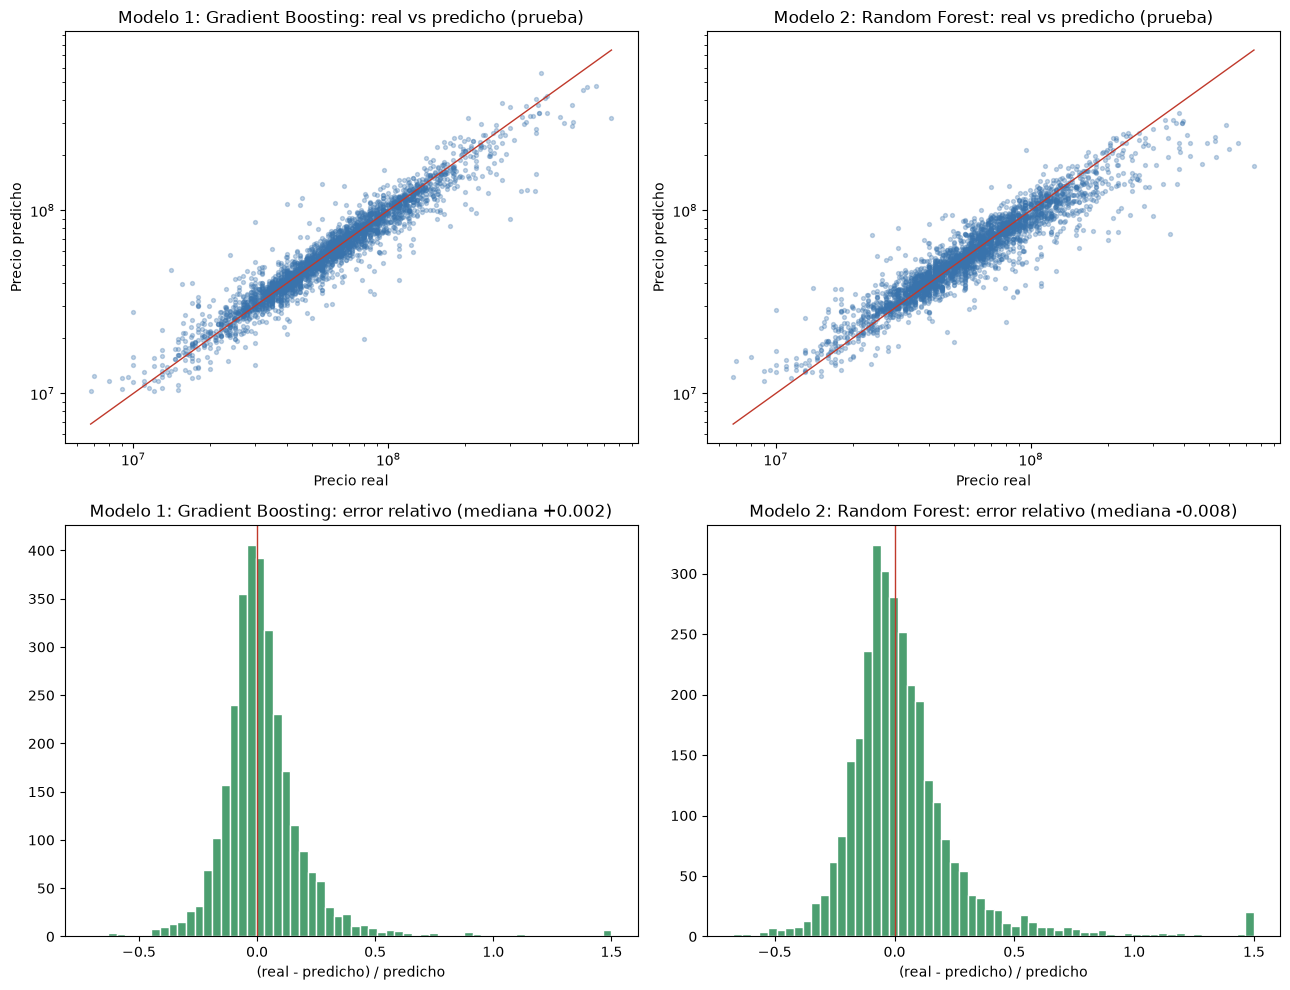

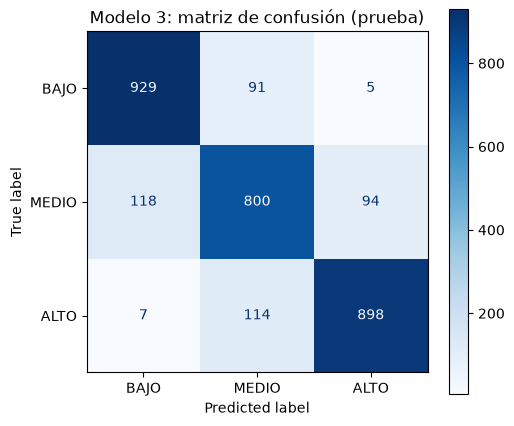

              precision    recall  f1-score   support

        BAJO       0.88      0.91      0.89      1025
       MEDIO       0.80      0.79      0.79      1012
        ALTO       0.90      0.88      0.89      1019

    accuracy                           0.86      3056
   macro avg       0.86      0.86      0.86      3056
weighted avg       0.86      0.86      0.86      3056



In [10]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 10))
for i, (nombre, modelo) in enumerate([("Modelo 1: Gradient Boosting", modelo_gb), ("Modelo 2: Random Forest", modelo_rf)]):
    pred = modelo.predict(X_test)
    ejes[0, i].scatter(y_test, pred, s=8, alpha=0.3, color="#3973ac")
    limite = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ejes[0, i].plot(limite, limite, color="#c0392b", linewidth=1)
    ejes[0, i].set_xscale("log"); ejes[0, i].set_yscale("log")
    ejes[0, i].set_title(f"{nombre}: real vs predicho (prueba)")
    ejes[0, i].set_xlabel("Precio real"); ejes[0, i].set_ylabel("Precio predicho")

    error_rel = (y_test - pred) / pred
    ejes[1, i].hist(error_rel.clip(-1, 1.5), bins=60, color="#4c9f70", edgecolor="white")
    ejes[1, i].axvline(0, color="#c0392b", linewidth=1)
    ejes[1, i].set_title(f"{nombre}: error relativo (mediana {error_rel.median():+.3f})")
    ejes[1, i].set_xlabel("(real - predicho) / predicho")
fig.tight_layout()
plt.show()

fig, eje = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(s_test, modelo_clf.predict(X_test), labels=pp.ETIQUETAS_SEGMENTO, cmap="Blues", ax=eje)
eje.set_title("Modelo 3: matriz de confusión (prueba)")
plt.show()

print(classification_report(s_test, modelo_clf.predict(X_test), labels=pp.ETIQUETAS_SEGMENTO, zero_division=0))

## 9. Interpretación: qué variables importan y dónde se equivoca el modelo
**Importancia por permutación:** se baraja una variable de entrada a la vez en validación y se mide cuánto empeora el modelo. Se hace sobre las 10 variables que escribe el usuario (no sobre las columnas codificadas), por lo que es directamente interpretable.

,Gradient Boosting (regresión),Random Forest (regresión),Regresión Logística (clasificación)
anio,0.370,0.304,0.315
marca,0.178,0.101,0.222
carroceria,0.114,0.120,0.089
cilindraje,0.067,0.066,0.005
kilometraje,0.041,0.045,0.007
modelo,0.037,0.017,0.145
transmision,0.028,0.053,0.008
combustible,0.021,0.026,0.008
departamento,0.001,0.000,0.005
tipo_vendedor,0.000,-0.000,0.008


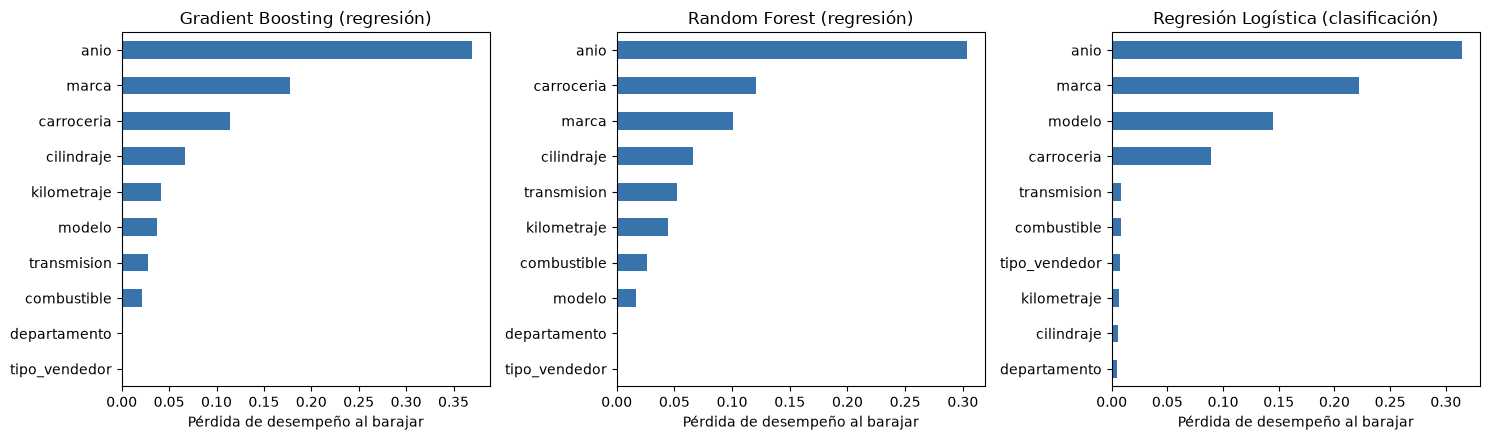

In [11]:
muestra = val.sample(n=min(len(val), 2000), random_state=SEMILLA)
Xm, ym, sm = muestra[pp.COLS_ENTRADA], muestra["precio"], muestra["segmento_precio"]

importancias = {}
for nombre, modelo, y_obj, puntaje in [
    ("Gradient Boosting (regresión)", modelo_gb, ym, "neg_root_mean_squared_log_error"),
    ("Random Forest (regresión)", modelo_rf, ym, "neg_root_mean_squared_log_error"),
    ("Regresión Logística (clasificación)", modelo_clf, sm, "f1_macro"),
]:
    r = permutation_importance(modelo, Xm, y_obj, scoring=puntaje, n_repeats=5, random_state=SEMILLA, n_jobs=1)
    importancias[nombre] = pd.Series(r.importances_mean, index=pp.COLS_ENTRADA)

tabla_importancia = pd.DataFrame(importancias)
display(tabla_importancia.sort_values(tabla_importancia.columns[0], ascending=False))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
for eje, (nombre, serie) in zip(ejes, importancias.items()):
    serie.sort_values().plot(kind="barh", ax=eje, color="#3973ac")
    eje.set_title(nombre)
    eje.set_xlabel("Pérdida de desempeño al barajar")
fig.tight_layout()
plt.show()

In [16]:
# Dónde se equivoca más el mejor modelo de regresión: error por segmento real de precio (prueba)
modelo_mejor = modelo_gb if mejor_reg == "Modelo 1: Gradient Boosting" else modelo_rf
pred_test = modelo_mejor.predict(X_test)
por_segmento = pd.DataFrame({
    "segmento": s_test.values,
    "abs_error": np.abs(y_test.values - pred_test),
    "ape_%": np.abs(y_test.values - pred_test) / y_test.values * 100,
}).groupby("segmento").agg(avisos=("abs_error", "size"), MAE=("abs_error", "mean"), MAPE_pct=("ape_%", "mean")).reindex(pp.ETIQUETAS_SEGMENTO)
print(f"Error por segmento, {mejor_reg}:")
display(por_segmento)

Error por segmento, Modelo 1: Gradient Boosting:


,avisos,MAE,MAPE_pct
segmento,,,
BAJO,1025,"3,672,773.066",12.917
MEDIO,1012,"5,618,187.938",9.835
ALTO,1019,"17,837,466.805",12.278


## 10. Indicadores de confianza para el frontend
- **Clasificación:** `predict_proba` entrega la probabilidad de cada segmento. La confianza es la probabilidad de la clase elegida.
- **Regresión:** un modelo de regresión da un número, no una probabilidad. Se construye un **intervalo empírico** con los errores relativos que el modelo cometió en validación: el 10 % y el 90 % de `(real − predicho) / predicho` definen un rango del 80 %. Se comprueba en prueba que ese rango cubre cerca del 80 % de los casos reales.
- **Acuerdo entre modelos:** la diferencia relativa entre las dos regresiones también es un indicador (si coinciden, hay más seguridad).

In [12]:
NIVEL = 0.80
q_inf, q_sup = (1 - NIVEL) / 2, 1 - (1 - NIVEL) / 2

intervalos = {}
for clave, modelo in (("gradient_boosting", modelo_gb), ("random_forest", modelo_rf)):
    pred_val = modelo.predict(X_val)
    error_rel_val = (y_val.values - pred_val) / pred_val
    inferior, superior = np.quantile(error_rel_val, [q_inf, q_sup])

    pred_t = modelo.predict(X_test)
    cobertura = float(np.mean((y_test.values >= pred_t * (1 + inferior)) & (y_test.values <= pred_t * (1 + superior))))
    intervalos[clave] = {"nivel": NIVEL, "error_relativo_inferior": float(inferior), "error_relativo_superior": float(superior), "cobertura_en_prueba": cobertura}
    print(f"{clave}: precio predicho x [{1 + inferior:.3f}, {1 + superior:.3f}] -> cobertura real en prueba {cobertura:.1%} (objetivo {NIVEL:.0%})")

# Acuerdo entre las dos regresiones (prueba)
dif_rel = np.abs(modelo_gb.predict(X_test) - modelo_rf.predict(X_test)) / modelo_rf.predict(X_test)
print(f"Diferencia relativa mediana entre los dos modelos de regresión: {np.median(dif_rel):.1%}")

# Confianza del clasificador
confianza = modelo_clf.predict_proba(X_test).max(axis=1)
acierto = modelo_clf.predict(X_test) == s_test.values
display(pd.DataFrame({
    "tramo_de_confianza": pd.cut(confianza, [0, 0.5, 0.7, 0.9, 1.0]),
    "acierto": acierto,
}).groupby("tramo_de_confianza", observed=True)["acierto"].agg(avisos="size", exactitud="mean"))

gradient_boosting: precio predicho x [0.834, 1.205] -> cobertura real en prueba 81.5% (objetivo 80%)
random_forest: precio predicho x [0.800, 1.279] -> cobertura real en prueba 82.0% (objetivo 80%)
Diferencia relativa mediana entre los dos modelos de regresión: 6.3%


,avisos,exactitud
tramo_de_confianza,,
"(0.0, 0.5]",42,0.548
"(0.5, 0.7]",664,0.645
"(0.7, 0.9]",845,0.850
"(0.9, 1.0]",1505,0.969


## 11. Persistencia y prueba del flujo del backend
Se guardan los tres modelos (cada uno es un `Pipeline` completo), los metadatos del entrenamiento y las opciones del formulario (categorías válidas y rangos) para que el frontend arme sus listas desplegables y el backend valide las entradas.

> **Importante:** los archivos `.joblib` dependen de la versión de scikit-learn con que se guardaron. La versión queda registrada en `metadatos_modelos.json`; el backend debe usar la misma (fíjala en `requirements.txt`).

In [13]:
rutas = {
    "regresion_gb": carpeta_modelos / "modelo_regresion_gb.joblib",
    "regresion_rf": carpeta_modelos / "modelo_regresion_rf.joblib",
    "clasificacion_segmento": carpeta_modelos / "modelo_clasificacion_segmento.joblib",
}
joblib.dump(modelo_gb, rutas["regresion_gb"], compress=3)
joblib.dump(modelo_rf, rutas["regresion_rf"], compress=3)
joblib.dump(modelo_clf, rutas["clasificacion_segmento"], compress=3)

def _json(o):
    return o.item() if hasattr(o, "item") else str(o)

def tabla_a_dict(tabla, modelo):
    sub = tabla[tabla["modelo"] == modelo].set_index("particion").drop(columns="modelo")
    return sub.to_dict(orient="index")

metadatos = {
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "versiones": {"python": platform.python_version(), "scikit_learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
    "semilla": SEMILLA,
    "validacion_cruzada": {"particiones": CV_FOLDS, "modo_rapido": MODO_RAPIDO},
    "columnas_entrada": pp.COLS_ENTRADA,
    "particiones": {"train": len(train), "val": len(val), "test": len(test)},
    "segmento": {"etiquetas": pp.ETIQUETAS_SEGMENTO, "cortes": cortes_info["cortes"]},
    "modelos": {
        "regresion_gb": {
            "algoritmo": "HistGradientBoostingRegressor sobre log1p(precio); predice en pesos",
            "archivo": rutas["regresion_gb"].name,
            "mejores_hiperparametros": {k.replace("regressor__modelo__", ""): v for k, v in busqueda_gb.best_params_.items()},
            "metricas": tabla_a_dict(resultados_reg, "Modelo 1: Gradient Boosting"),
            "intervalo_empirico": intervalos["gradient_boosting"],
        },
        "regresion_rf": {
            "algoritmo": "RandomForestRegressor sobre log1p(precio); predice en pesos",
            "archivo": rutas["regresion_rf"].name,
            "mejores_hiperparametros": {k.replace("regressor__modelo__", ""): v for k, v in busqueda_rf.best_params_.items()},
            "metricas": tabla_a_dict(resultados_reg, "Modelo 2: Random Forest"),
            "intervalo_empirico": intervalos["random_forest"],
        },
        "clasificacion_segmento": {
            "algoritmo": "LogisticRegression (multinomial, regularización L2) sobre segmento_precio",
            "archivo": rutas["clasificacion_segmento"].name,
            "clases": [str(c) for c in modelo_clf.classes_],
            "mejores_hiperparametros": {k.replace("modelo__", ""): v for k, v in busqueda_clf.best_params_.items()},
            "metricas": tabla_a_dict(resultados_clf, "Modelo 3: Regresión Logística"),
        },
    },
}
with open(carpeta_modelos / "metadatos_modelos.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, indent=2, ensure_ascii=False, default=_json)

# Opciones del formulario (categorías vistas en entrenamiento y rangos de validación)
opciones = {
    "marca": sorted(train["marca"].dropna().unique().tolist()),
    "modelos_por_marca": {m: sorted(g["modelo"].dropna().unique().tolist()) for m, g in train.groupby("marca")},
    "combustible": sorted(train["combustible"].dropna().unique().tolist()),
    "transmision": sorted(train["transmision"].dropna().unique().tolist()),
    "carroceria": sorted(train["carroceria"].dropna().unique().tolist()),
    "departamento": sorted(train["departamento"].dropna().unique().tolist()),
    "tipo_vendedor": sorted(train["tipo_vendedor"].dropna().unique().tolist()),
    "rangos": {
        "anio": [int(train["anio"].min()), pp.ANIO_REFERENCIA + 1],
        "kilometraje": [0, pp.KM_MAX],
        "cilindraje": [0, pp.CILINDRAJE_MAX],
    },
}
with open(carpeta_modelos / "opciones_formulario.json", "w", encoding="utf-8") as f:
    json.dump(opciones, f, indent=2, ensure_ascii=False, default=_json)

for ruta in list(rutas.values()) + [carpeta_modelos / "metadatos_modelos.json", carpeta_modelos / "opciones_formulario.json"]:
    kb = ruta.stat().st_size / 1024
    print(f"{ruta.name:40s} {kb:10,.1f} KB" + ("   <-- supera 90 MB: GitHub lo rechazará; sube min_samples_leaf o baja n_estimators" if kb > 90 * 1024 else ""))

modelo_regresion_gb.joblib                    888.3 KB
modelo_regresion_rf.joblib                  2,134.8 KB
modelo_clasificacion_segmento.joblib           15.3 KB
metadatos_modelos.json                          4.4 KB
opciones_formulario.json                       16.9 KB


In [14]:
# Simulación de lo que hará el backend: cargar una vez, recibir las 10 columnas crudas y consolidar la respuesta
modelos_cargados = {nombre: joblib.load(ruta) for nombre, ruta in rutas.items()}

entrada_formulario = {
    "marca": "chevrolet", "modelo": "Tracker", "anio": 2020, "kilometraje": 60000,
    "combustible": "Gasolina", "transmision": "Automática", "cilindraje": 1200,
    "carroceria": "Camionetas", "departamento": "Antioquia", "tipo_vendedor": "Particular",
}
fila = pd.DataFrame([entrada_formulario])

def respuesta_json(fila):
    out = {}
    for clave, nombre_intervalo in (("regresion_gb", "gradient_boosting"), ("regresion_rf", "random_forest")):
        precio = float(modelos_cargados[clave].predict(fila)[0])
        iv = metadatos["modelos"][clave]["intervalo_empirico"]
        out[clave] = {
            "precio_estimado": round(precio),
            "rango_80": [round(precio * (1 + iv["error_relativo_inferior"])), round(precio * (1 + iv["error_relativo_superior"]))],
        }
    clf = modelos_cargados["clasificacion_segmento"]
    proba = clf.predict_proba(fila)[0]
    probas = {str(c): round(float(p), 4) for c, p in zip(clf.classes_, proba)}
    segmento = max(probas, key=probas.get)
    out["clasificacion_segmento"] = {"segmento": segmento, "confianza": probas[segmento], "probabilidades": probas}
    return out

print(json.dumps(respuesta_json(fila), indent=2, ensure_ascii=False))

# Las predicciones recargadas deben coincidir con las originales
assert np.allclose(modelos_cargados["regresion_gb"].predict(X_test.head(100)), modelo_gb.predict(X_test.head(100)))
assert np.allclose(modelos_cargados["regresion_rf"].predict(X_test.head(100)), modelo_rf.predict(X_test.head(100)))
assert (modelos_cargados["clasificacion_segmento"].predict(X_test.head(100)) == modelo_clf.predict(X_test.head(100))).all()
print("OK: los modelos recargados predicen igual que los originales.")

{
  "regresion_gb": {
    "precio_estimado": 65591146,
    "rango_80": [
      54728894,
      79020025
    ]
  },
  "regresion_rf": {
    "precio_estimado": 67796928,
    "rango_80": [
      54215105,
      86710959
    ]
  },
  "clasificacion_segmento": {
    "segmento": "MEDIO",
    "confianza": 0.8706,
    "probabilidades": {
      "ALTO": 0.0926,
      "BAJO": 0.0368,
      "MEDIO": 0.8706
    }
  }
}
OK: los modelos recargados predicen igual que los originales.


## Resumen para el informe
La tabla reúne las métricas finales **en prueba** de los modelos definitivos frente a sus baselines, lista para copiar a la sección 5.4 del informe.

In [15]:
resumen_reg = resultados_reg[resultados_reg["particion"] == "test"].drop(columns="particion").set_index("modelo")
display(resumen_reg)
resumen_clf = resultados_clf[resultados_clf["particion"] == "test"].drop(columns="particion").set_index("modelo")
display(resumen_clf)

,MAE,RMSE,MAPE_%,R2,R2_log
modelo,,,,,
Baseline (mediana),"33,707,739.732","59,034,260.526",53.379,-0.063,-0.001
Modelo 1: Gradient Boosting,"9,040,110.360","21,255,993.760",11.684,0.862,0.920
Modelo 2: Random Forest,"12,122,207.438","29,784,352.742",14.795,0.729,0.877


,accuracy,precision_macro,recall_macro,F1_macro,AUC_ROC_macro
modelo,,,,,
Baseline (proporción de clases),0.331,0.110,0.333,0.166,0.500
Referencia: Random Forest,0.844,0.842,0.843,0.842,0.957
Modelo 3: Regresión Logística,0.860,0.859,0.859,0.859,0.959
